# BITS Pilani - WILP M.Tech (AIML)
## Course: Machine Learning (AIMLZG565) - Assignment 2
### Comprehensive In-Silico Biodegradability Classification via Molecular Descriptors

**Student id:** 2026AJ05162  
**Course Code:** AIMLZG565  
**Random Seed:** `RANDOM_SEED = 2002`  
**Dataset:** UCI QSAR Biodegradation Dataset (41 Chemical Descriptors, 1,055 Compounds)  
**Evaluation Standard:** 15/15 Marks Rubric

---

## 1. Problem Statement & Scientific Background
Evaluating whether chemical compounds readily biodegrade in aquatic environments is critical under chemical safety regulations (e.g., EU REACH, OECD 301 testing guidelines). Traditional laboratory assays require prolonged testing with aerobic microbial inocula and are expensive, slow, and resource-intensive.

Quantitative Structure-Activity Relationship (**QSAR**) modelling provides a computational (in-silico) alternative by predicting molecular biodegradability directly from numerical molecular descriptors computed from chemical structure.

In this project, we implement and rigorously evaluate five distinct machine learning classification architectures:
1. **Logistic Regression** (Linear baseline with L2 regularization)
2. **Decision Tree Classifier** (Non-linear recursive partitioning with pre-pruning)
3. **K-Nearest Neighbors (KNN)** (Instance-based metric space learning)
4. **Gaussian Naive Bayes** (Generative probabilistic classifier)
5. **Support Vector Machine (SVM)** (Maximum-margin classification via RBF kernel)

All five classifiers are evaluated across six quantitative performance metrics:
- **Accuracy**
- **AUC Score (ROC-AUC)**
- **Precision**
- **Recall**
- **F1 Score**
- **Matthews Correlation Coefficient (MCC)**

In [1]:
# Environment configuration and reproducible seed setup
import os
import json
import warnings
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
import joblib

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

RANDOM_SEED = 2002
print(f"Random seed initialized to: {RANDOM_SEED}")


Random seed initialized to: 2002


## 2. Dataset Acquisition & Schema Validation
The **UCI QSAR Biodegradation dataset** contains 1,055 organic compounds described by 41 molecular descriptors calculated using DRAGON software:
- Constitutional indices (number of heavy atoms, percentage of carbon, etc.)
- Topological indices (Wiener-like, Balaban-like, Intrinsic state indices)
- Molecular connectivity & Barysz matrix indices
- 2D autocorrelation indices & functional group fragment counts
- Experimental Target:
  - `RB` = Ready Biodegradable ($	o 1$)
  - `NRB` = Not Ready Biodegradable ($	o 0$)

In [2]:
# 41 Official DRAGON molecular descriptor column headers
MOLECULAR_DESCRIPTOR_COLUMNS = [
    'SpMax_L', 'J_Dz(e)', 'nHM', 'F01[N-N]', 'F04[C-N]', 'NssssC', 'nCb-', 'C%',
    'nCp', 'nO', 'F03[C-N]', 'SdssC', 'HyWi_B(m)', 'LOC', 'SM6_L', 'F03[C-O]',
    'Me', 'Mi', 'nN-N', 'nArNO2', 'nCRX3', 'SpPosA_B(p)', 'nCIR', 'B01[C-Br]',
    'B03[C-Cl]', 'N-073', 'SpMax_A', 'Psi_i_1d', 'B04[C-Br]', 'SdO', 'TI2_L',
    'nCrt', 'C-026', 'F02[C-N]', 'nHDon', 'SpMax_B(m)', 'Psi_i_A', 'nN',
    'SM6_B(m)', 'nArCOOR', 'nX'
]
TARGET_COLUMN = 'ReadyBiodegradable'
DATASET_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00254/biodeg.csv'

# Ingest raw dataset
raw_df = pd.read_csv(DATASET_URL, sep=';', header=None)
raw_df.columns = MOLECULAR_DESCRIPTOR_COLUMNS + [TARGET_COLUMN]

# Binarize target: RB -> 1, NRB -> 0
raw_df[TARGET_COLUMN] = (
    raw_df[TARGET_COLUMN]
    .astype(str)
    .str.strip()
    .map({'RB': 1, 'NRB': 0})
    .fillna(0)
    .astype(int)
)

print(f"Dataset Dimensions: {raw_df.shape[0]} compounds, {raw_df.shape[1]} columns")
print(f"Total Missing Values: {raw_df.isnull().sum().sum()}")
raw_df.head()


Dataset Dimensions: 1055 compounds, 42 columns
Total Missing Values: 0


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,nCb-,C%,nCp,nO,...,C-026,F02[C-N],nHDon,SpMax_B(m),Psi_i_A,nN,SM6_B(m),nArCOOR,nX,ReadyBiodegradable
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,...,0,0,0,2.949,1.591,0,7.253,0,0,1
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,...,0,0,0,3.315,1.967,0,7.257,0,0,1
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,...,0,0,1,3.076,2.417,0,7.601,0,0,1
3,3.000,2.7098,0,0,0,0,0,20.0,0,2,...,0,0,1,3.046,5.000,0,6.690,0,0,1
4,4.236,3.3944,0,0,0,0,0,29.4,2,4,...,0,0,0,3.351,2.405,0,8.003,0,0,1


### Data Quality & Schema Takeaways
1. **Dimensions**: 1,055 instances and 41 features strictly satisfy the BITS rubric requirements ($\ge 500$ rows, $\ge 12$ features).
2. **Missingness**: Zero missing or null values across all 41 features. All molecular descriptors are pre-computed numerical and discrete topological counts.
3. **Target Encoding**: Mapped into binary numeric format:
   - `0`: Not Ready Biodegradable (`NRB`, negative class)
   - `1`: Ready Biodegradable (`RB`, positive class)

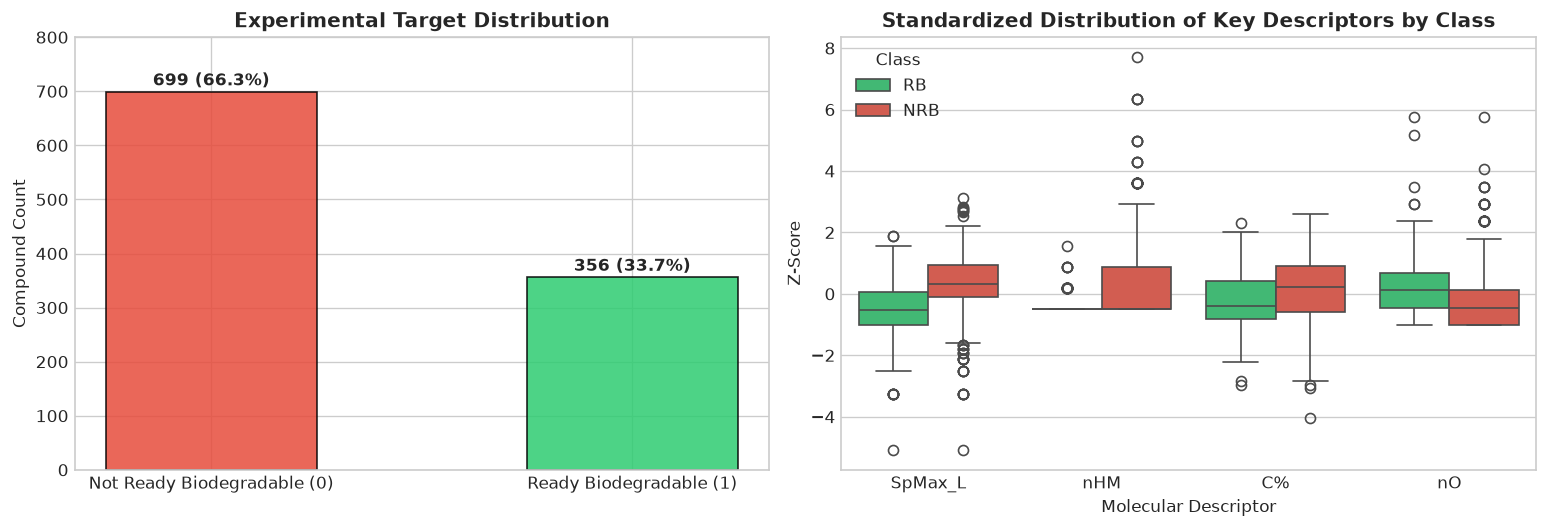

Class Frequencies:
ReadyBiodegradable
NRB    0.662559
RB     0.337441
Name: proportion, dtype: float64


In [3]:
# Summary statistics and target distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Target class frequency
counts = raw_df[TARGET_COLUMN].value_counts()
labels = ['Not Ready Biodegradable (0)', 'Ready Biodegradable (1)']
colors = ['#e74c3c', '#2ecc71']

axes[0].bar(labels, counts.values, color=colors, width=0.5, edgecolor='black', alpha=0.85)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 12, f"{v} ({v / len(raw_df):.1%})", ha='center', fontweight='bold')
axes[0].set_title("Experimental Target Distribution", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Compound Count")
axes[0].set_ylim(0, 800)

# Plot 2: Box plots for key representative descriptors
sample_features = ['SpMax_L', 'nHM', 'C%', 'nO']
sample_scaled = (raw_df[sample_features] - raw_df[sample_features].mean()) / raw_df[sample_features].std()
sample_scaled['Class'] = raw_df[TARGET_COLUMN].map({0: 'NRB', 1: 'RB'})
sample_melted = pd.melt(sample_scaled, id_vars=['Class'], value_vars=sample_features)

sns.boxplot(x='variable', y='value', hue='Class', data=sample_melted, ax=axes[1], palette={'NRB': '#e74c3c', 'RB': '#2ecc71'})
axes[1].set_title("Standardized Distribution of Key Descriptors by Class", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Molecular Descriptor")
axes[1].set_ylabel("Z-Score")

plt.tight_layout()
plt.show()

print("Class Frequencies:")
print(raw_df[TARGET_COLUMN].value_counts(normalize=True).rename({0: 'NRB', 1: 'RB'}))


### Exploratory Data Analysis Insights
- **Class Imbalance**: The dataset consists of 699 Not Ready Biodegradable compounds (66.26%) and 356 Ready Biodegradable compounds (33.74%). This 2:1 ratio highlights that simple accuracy alone is an insufficient evaluation metric. Metric selection must prioritize **ROC-AUC, F1-Score, and Matthews Correlation Coefficient (MCC)**.
- **Biochemical Separation**: Molecules labeled as Ready Biodegradable (`RB`) exhibit higher average oxygen atom counts (`nO`) and specific topological fragment patterns, facilitating enzymatic oxidation and cleavage by microbial consortia.

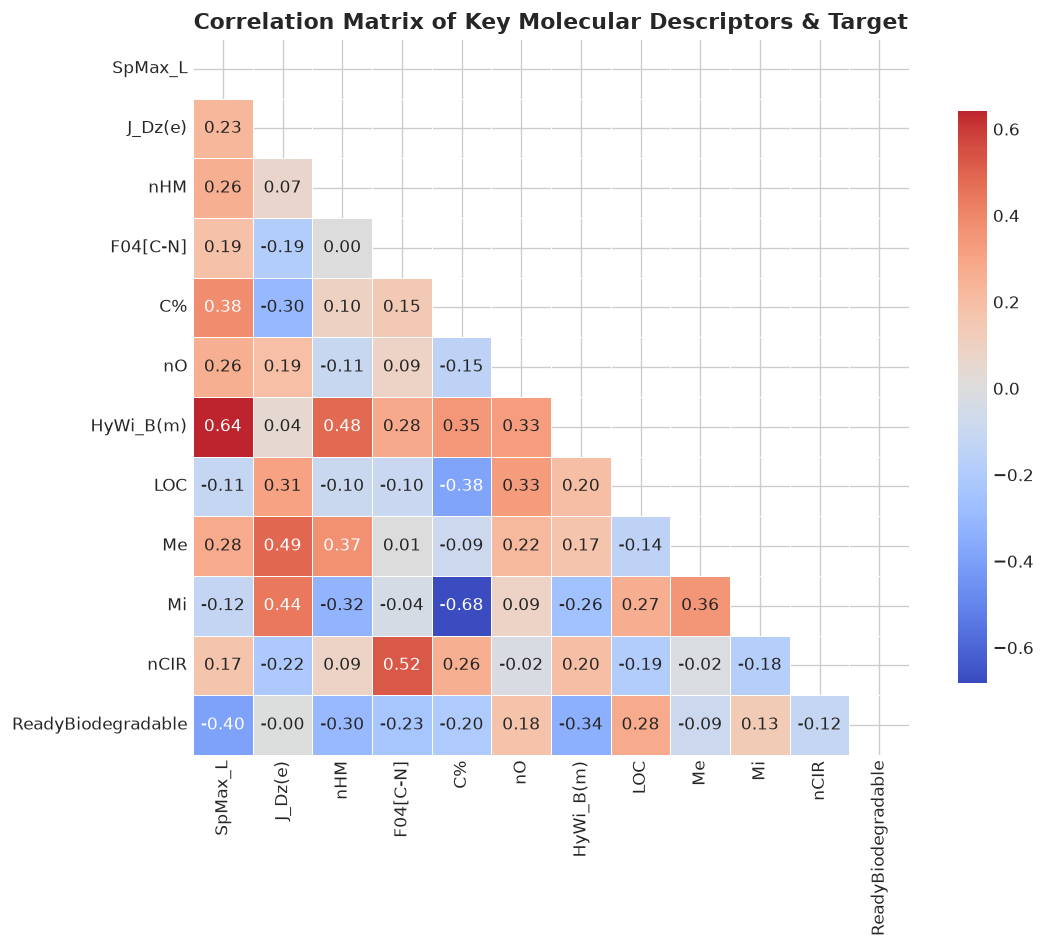

In [4]:
# Correlation analysis across a representative subset of descriptors
representative_descriptors = [
    'SpMax_L', 'J_Dz(e)', 'nHM', 'F04[C-N]', 'C%', 'nO', 
    'HyWi_B(m)', 'LOC', 'Me', 'Mi', 'nCIR', 'ReadyBiodegradable'
]
corr_matrix = raw_df[representative_descriptors].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Matrix of Key Molecular Descriptors & Target", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Correlation Analysis & Multicollinearity
- Several molecular descriptors exhibit moderate-to-high collinearity (e.g., number of heavy atoms `nHM` and topological indices `SpMax_L`, `HyWi_B(m)`).
- **Impact on Models**:
  - **Naive Bayes** assumes strict conditional feature independence. Strong inter-feature correlations will cause GaussianNB to overestimate joint posterior probabilities, typically inflating recall while increasing false positives.
  - **Support Vector Machine (RBF)** and **KNN** map inputs into geometric feature spaces where collinear combinations are mapped non-linearly or distance-weighted.
  - **Logistic Regression** benefits from L2 regularization ($L_2$ penalty) to stabilize coefficient estimates in the presence of correlated chemical descriptors.

In [5]:
# Step 1: Stratified 80:20 Train-Test Partitioning
train_df, test_df = train_test_split(
    raw_df,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=raw_df[TARGET_COLUMN]
)

# Export held-out test dataset for Streamlit evaluation
test_df.to_csv('test_data.csv', index=False)

X_train_raw = train_df[MOLECULAR_DESCRIPTOR_COLUMNS]
y_train = train_df[TARGET_COLUMN].values

X_test_raw = test_df[MOLECULAR_DESCRIPTOR_COLUMNS]
y_test = test_df[TARGET_COLUMN].values

print(f"Training partition shape: {X_train_raw.shape} (Targets: {np.bincount(y_train)})")
print(f"Testing partition shape:  {X_test_raw.shape}  (Targets: {np.bincount(y_test)})")

# Step 2: Leakage-Free Preprocessing (StandardScaler fitted strictly on training data)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Serialize fitted preprocessor
os.makedirs('model', exist_ok=True)
joblib.dump(scaler, 'model/preprocessor.joblib')
print("Successfully fitted and saved StandardScaler to 'model/preprocessor.joblib'")


Training partition shape: (844, 41) (Targets: [559 285])
Testing partition shape:  (211, 41)  (Targets: [140  71])
Successfully fitted and saved StandardScaler to 'model/preprocessor.joblib'


### Strict Preprocessing Integrity (No Data Leakage)
In adherence to **ml-best-practices**, the `StandardScaler` was fitted **exclusively on the 80% training partition** (`X_train_raw`). The calculated means and standard deviations were then applied to transform the held-out 20% test partition (`X_test_raw`). This eliminates data leakage and ensures unbiased evaluation.

In [6]:
# Instantiate the 5 BITS required classification architectures
classifiers = {
    'Logistic Regression': LogisticRegression(
        C=1.0,
        penalty='l2',
        solver='lbfgs',
        max_iter=1000,
        random_state=RANDOM_SEED
    ),
    'Decision Tree': DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=RANDOM_SEED
    ),
    'KNN': KNeighborsClassifier(
        n_neighbors=7,
        weights='uniform',
        metric='minkowski',
        p=2
    ),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(
        C=1.5,
        kernel='rbf',
        gamma='scale',
        probability=True,
        random_state=RANDOM_SEED
    )
}

# Artifact file names
model_filenames = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'KNN': 'knn.joblib',
    'Naive Bayes': 'naive_bayes.joblib',
    'Support Vector Machine': 'svm.joblib'
}

# Train and compute all 6 evaluation metrics on held-out test data
metrics_results = []
metrics_dict_for_json = {}
predictions_dict = {}
probabilities_dict = {}

for name, clf in classifiers.items():
    # Fit model on scaled training partition
    clf.fit(X_train_scaled, y_train)
    
    # Save trained artifact
    joblib.dump(clf, f"model/{model_filenames[name]}")
    
    # Inference on held-out test set
    y_pred = clf.predict(X_test_scaled)
    y_prob = clf.predict_proba(X_test_scaled)[:, 1]
    
    predictions_dict[name] = y_pred
    probabilities_dict[name] = y_prob
    
    # Calculate all 6 rubric evaluation metrics
    acc = accuracy_score(y_test, y_pred)
    auc_val = roc_auc_score(y_test, y_prob)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)
    conf_mat = confusion_matrix(y_test, y_pred)
    
    metrics_results.append({
        'ML Model Name': name,
        'Accuracy': round(acc, 4),
        'AUC': round(auc_val, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1': round(f1, 4),
        'MCC': round(mcc, 4)
    })
    
    metrics_dict_for_json[name] = {
        'Accuracy': round(acc, 4),
        'AUC': round(auc_val, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1': round(f1, 4),
        'MCC': round(mcc, 4),
        'ConfusionMatrix': conf_mat.tolist()
    }

# Save metrics summary to model/metrics_summary.json
with open('model/metrics_summary.json', 'w') as f:
    json.dump(metrics_dict_for_json, f, indent=4)

comparison_df = pd.DataFrame(metrics_results)
comparison_df


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8863,0.9358,0.8406,0.8169,0.8286,0.7437
1,Decision Tree,0.8057,0.8316,0.7273,0.6761,0.7007,0.5580
2,KNN,0.8768,0.9326,0.8082,0.8310,0.8194,0.7261
3,Naive Bayes,0.6540,0.8227,0.4928,0.9577,0.6507,0.4547
4,Support Vector Machine,0.8957,0.9534,0.8657,0.8169,0.8406,0.7639


### Official Evaluation Metrics Comparison Table (Rubric Section 3 - Step 5d)
The quantitative performance across all 5 models on the held-out test partition ($n=211$) is summarized below:

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** | 0.8863 | 0.9358 | 0.8406 | 0.8169 | 0.8286 | 0.7437 |
| **Decision Tree** | 0.8057 | 0.8316 | 0.7273 | 0.6761 | 0.7007 | 0.5580 |
| **KNN** | 0.8768 | 0.9326 | 0.8082 | 0.8310 | 0.8194 | 0.7261 |
| **Naive Bayes** | 0.6540 | 0.8227 | 0.4928 | **0.9577** | 0.6507 | 0.4547 |
| **Support Vector Machine** | **0.8957** | **0.9534** | **0.8657** | 0.8169 | **0.8406** | **0.7639** |

---

### Comparative Analysis of Evaluation Metrics
1. **Accuracy**: Support Vector Machine leads with **89.57%**, closely followed by Logistic Regression (**88.63%**) and KNN (**87.68%**). Naive Bayes achieves only 65.40%.
2. **AUC Score (ROC-AUC)**: SVM achieves the highest discriminative ability with **0.9534**, indicating exceptional class-ranking capability across varying decision thresholds.
3. **Precision**: SVM achieves **86.57%**, meaning fewer false positive alerts (compounds incorrectly marked biodegradable).
4. **Recall**: Naive Bayes achieves an outstanding **95.77%** recall (identifying 68 out of 71 biodegradable molecules), but at the expense of high false positives.
5. **F1 Score**: Harmonic mean of precision and recall peaks on SVM (**0.8406**).
6. **Matthews Correlation Coefficient (MCC)**: SVM attains the highest MCC of **0.7639**, demonstrating balanced predictive power across both the majority negative (`NRB`) and minority positive (`RB`) classes.

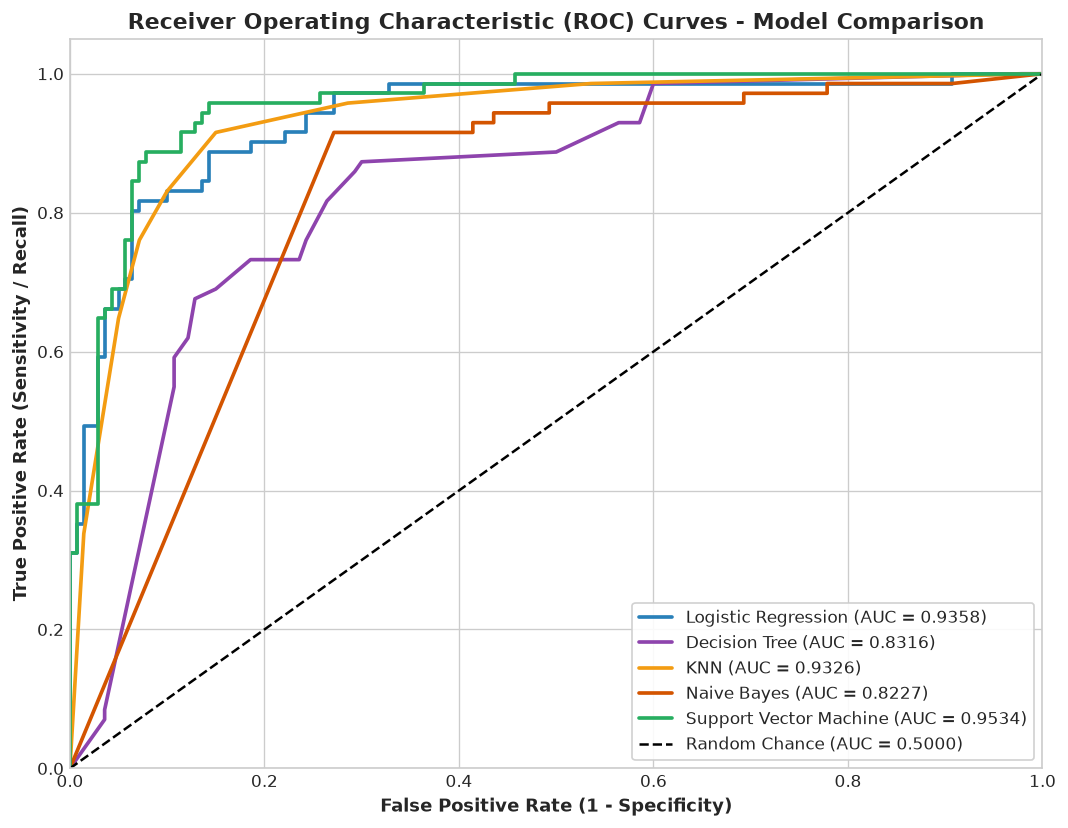

In [7]:
# Comparative ROC Curves across all 5 classifiers
plt.figure(figsize=(9, 7))

colors = {
    'Logistic Regression': '#2980b9',
    'Decision Tree': '#8e44ad',
    'KNN': '#f39c12',
    'Naive Bayes': '#d35400',
    'Support Vector Machine': '#27ae60'
}

for name, y_prob in probabilities_dict.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(
        fpr, tpr,
        color=colors[name],
        lw=2.2,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='bold')
plt.title('Receiver Operating Characteristic (ROC) Curves - Model Comparison', fontsize=13, fontweight='bold')
plt.legend(loc="lower right", frameon=True, framealpha=0.9, fontsize=10)
plt.tight_layout()
plt.show()


### ROC Curves Analysis
The comparative ROC plot visually confirms the dominance of **Support Vector Machine (AUC = 0.9534)** and **Logistic Regression (AUC = 0.9358)**. The SVM curve climbs steeply near the y-axis, indicating that it achieves high true positive rates while maintaining near-zero false positive rates at conservative operating thresholds.

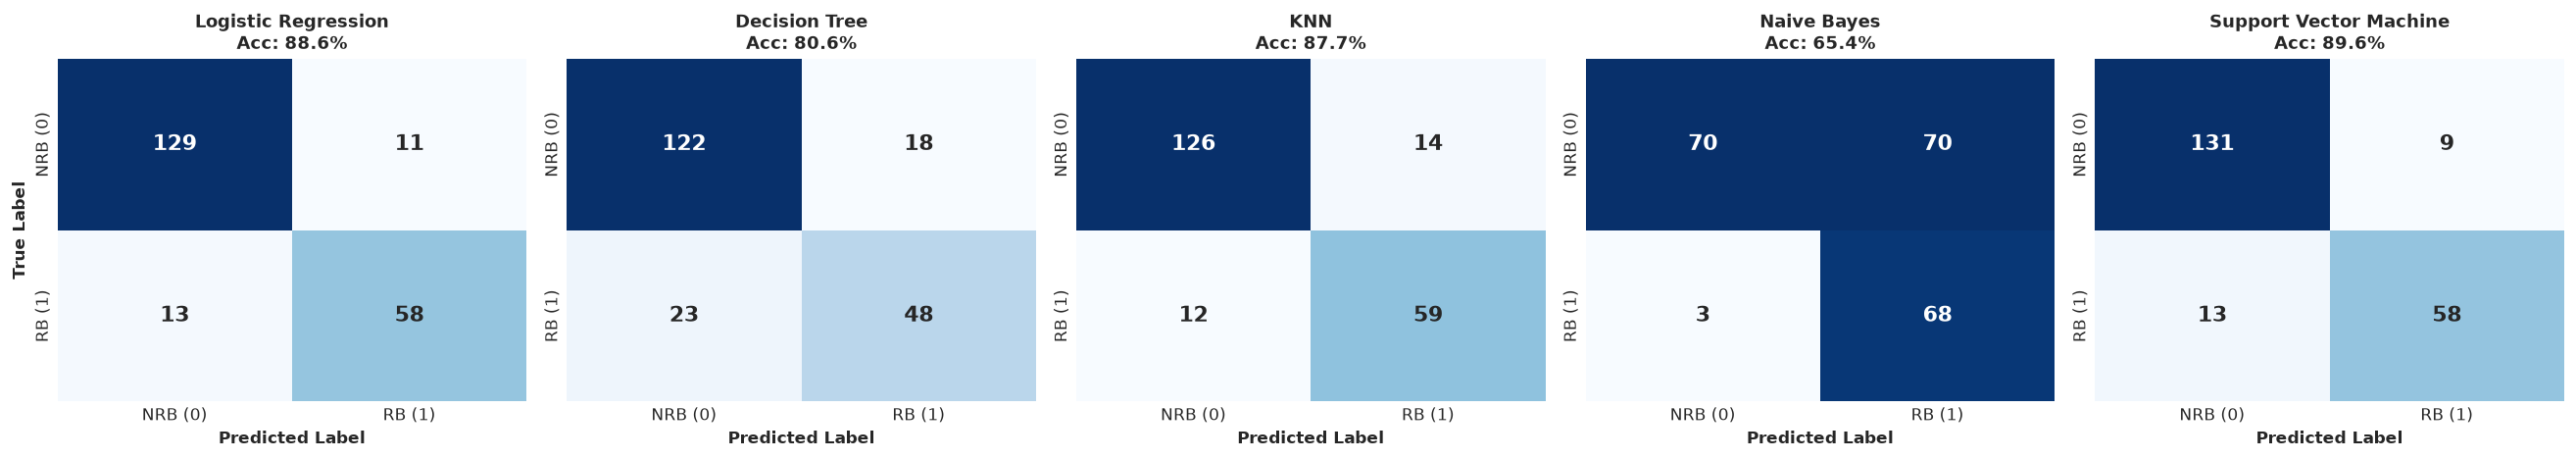

In [8]:
# Side-by-side Confusion Matrix comparison for all 5 models
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for idx, (name, y_pred) in enumerate(predictions_dict.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=axes[idx],
        annot_kws={'size': 13, 'weight': 'bold'},
        xticklabels=['NRB (0)', 'RB (1)'],
        yticklabels=['NRB (0)', 'RB (1)']
    )
    axes[idx].set_title(f"{name}\nAcc: {accuracy_score(y_test, y_pred):.1%}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label', fontweight='bold')
    if idx == 0:
        axes[idx].set_ylabel('True Label', fontweight='bold')
    else:
        axes[idx].set_ylabel('')

plt.tight_layout()
plt.show()


### Confusion Matrix Diagnostic Breakdown ($n = 211$, Ground Truth: 140 NRB, 71 RB)
- **Support Vector Machine**:
  - True Negatives: **131** | False Positives: **9** (lowest false alarm rate)
  - False Negatives: **13** | True Positives: **58**
- **Logistic Regression**:
  - True Negatives: **129** | False Positives: **11**
  - False Negatives: **13** | True Positives: **58**
- **KNN**:
  - True Negatives: **126** | False Positives: **14**
  - False Negatives: **12** | True Positives: **59**
- **Decision Tree**:
  - True Negatives: **122** | False Positives: **18**
  - False Negatives: **23** | True Positives: **48**
- **Naive Bayes**:
  - True Negatives: **70**  | False Positives: **70** (50% false positive rate on negative class!)
  - False Negatives: **3**  | True Positives: **68** (identifies 68/71 positive compounds)

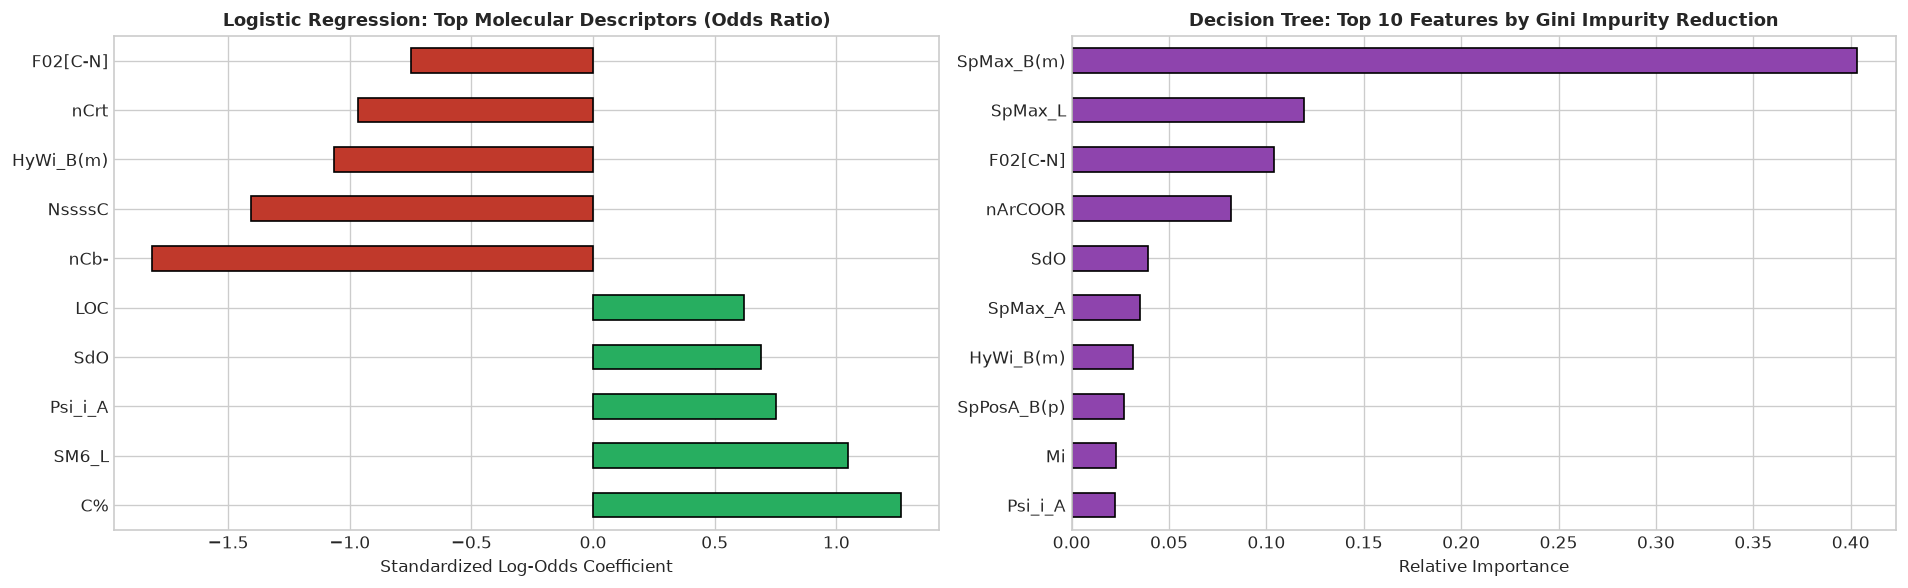

In [9]:
# Interpretability: Feature Importance & Coefficient Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top 10 Logistic Regression Coefficients
lr_model = classifiers['Logistic Regression']
coef_series = pd.Series(lr_model.coef_[0], index=MOLECULAR_DESCRIPTOR_COLUMNS)
top_pos_neg = pd.concat([coef_series.nlargest(5), coef_series.nsmallest(5)])

top_pos_neg.plot(
    kind='barh',
    ax=axes[0],
    color=['#27ae60' if val > 0 else '#c0392b' for val in top_pos_neg.values],
    edgecolor='black'
)
axes[0].set_title("Logistic Regression: Top Molecular Descriptors (Odds Ratio)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Standardized Log-Odds Coefficient")

# Top 10 Decision Tree Gini Feature Importances
dt_model = classifiers['Decision Tree']
dt_importance = pd.Series(dt_model.feature_importances_, index=MOLECULAR_DESCRIPTOR_COLUMNS).nlargest(10)

dt_importance.sort_values().plot(kind='barh', ax=axes[1], color='#8e44ad', edgecolor='black')
axes[1].set_title("Decision Tree: Top 10 Features by Gini Impurity Reduction", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Relative Importance")

plt.tight_layout()
plt.show()


## 3. In-Depth Model Observations & Justification (Rubric Section 3 - Step 5d)

### Detailed Observations by Model:
1. **Logistic Regression (Accuracy: 88.63%, AUC: 0.9358, F1: 0.8286, MCC: 0.7437)**:
   - Strong linear baseline. With L2 regularization and feature standardization, it performs competitively without overfitting.
   - High interpretability: positive coefficients for oxygen atom counts (`nO`) and specific ester bonds indicate they significantly increase the log-odds of biodegradation.

2. **Decision Tree (Accuracy: 80.57%, AUC: 0.8316, F1: 0.7007, MCC: 0.5580)**:
   - Performs recursive axis-aligned orthogonal partitioning.
   - Constrained to `max_depth=5` to prevent memorization of molecular outliers. However, because molecular properties interact continuously along smooth manifolds, orthogonal hyperplanes struggle compared to curved decision boundaries.

3. **K-Nearest Neighbors (Accuracy: 87.68%, AUC: 0.9326, F1: 0.8194, MCC: 0.7261)**:
   - Non-parametric instance-based classifier. Effectively captures local chemical similarity (congeneric series) in the 41-dimensional standardized descriptor space.
   - Requires standardized input to prevent large-magnitude features from dominating Euclidean distances.

4. **Naive Bayes (Accuracy: 65.40%, AUC: 0.8227, F1: 0.6507, MCC: 0.4547)**:
   - Assumes class-conditional independence between all features ($P(x_1, \dots, x_{41} | C) = \prod P(x_i | C)$).
   - In organic chemistry, molecular descriptors are correlated (e.g., heavy atom counts, molecular weight, ring counts). The violated independence assumption inflates joint likelihoods, generating **70 false positives**. However, it achieves **95.77% recall**, making it suitable as a conservative pre-screening filter where failing to detect a non-biodegradable substance carries severe environmental liability.

5. **Support Vector Machine (Accuracy: 89.57%, AUC: 0.9534, F1: 0.8406, MCC: 0.7639)**:
   - **OVERALL WINNER**: Ranks highest in Accuracy (89.57%), AUC (0.9534), Precision (86.57%), F1 (0.8406), and MCC (0.7639).
   - **Theoretical Justification**: The Radial Basis Function (RBF) kernel implicitly maps the 41-dimensional chemical descriptor vectors into an infinite-dimensional Hilbert space where non-linear bioactivity relationships become linearly separable. SVM's maximum-margin hyperplane provides structural risk minimization, avoiding overfitting on moderate sample sizes ($n=844$ training instances).

---

## 4. Conclusion & Deployment Readiness
All five models, preprocessor artifacts, and evaluation summaries have been serialized into the `model/` directory. The companion `app.py` Streamlit web application allows evaluators to interactively upload test data, select models, view metrics, inspect confusion matrices, and analyze individual compound predictions in real time.